# Machine Learning — Practical Session 2: Python for Standardized PCA
**National Higher School of Advanced Technologies (ENSTA)**  
*Academic Year: 2026–2027*  
**Student:** Anes Benrahmoune  
**Level:** 4th Year Student (Artificial Intelligence Specialty)  
**Group:** Group 1  
**GitHub:** [BENRAHMOUNEANES](https://github.com/BENRAHMOUNEANES)  
**Course:** Machine Learning  

---

## Objective
Implement **Principal Component Analysis (PCA)** from scratch using Python, linear algebra, and NumPy, and compare the theoretical and numerical results with the predefined standardized PCA implementation provided by **Scikit-learn**.


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

%matplotlib inline
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({'figure.autolayout': True, 'font.sans-serif': 'DejaVu Sans', 'font.size': 10})


---
## Dataset: Student Grades in Four Academic Subjects
Consider the grades of six students ($S_1, \dots, S_6$) evaluated across four subjects:
- Mathematics
- Statistics
- Programming
- Algorithms


In [11]:
# 1. Load dataset
df_grades = pd.DataFrame({
    "Student": ["S1", "S2", "S3", "S4", "S5", "S6"],
    "Mathematics": [12, 15, 8, 17, 10, 14],
    "Statistics": [11, 14, 9, 16, 12, 15],
    "Programming": [14, 16, 10, 18, 11, 13],
    "Algorithms": [13, 15, 9, 17, 10, 14]
}).set_index("Student")
display(df_grades)

# 2. Dimensions & statistics
print(f"Shape: {df_grades.shape}")
display(df_grades.describe().round(3))


,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,12,11,14,13
S2,15,14,16,15
S3,8,9,10,9
S4,17,16,18,17
S5,10,12,11,10
S6,14,15,13,14


Shape: (6, 4)


,Mathematics,Statistics,Programming,Algorithms
count,6.000,6.000,6.000,6.000
mean,12.667,12.833,13.667,13.000
std,3.327,2.639,3.011,3.033
min,8.000,9.000,10.000,9.000
25%,10.500,11.250,11.500,10.750
50%,13.000,13.000,13.500,13.500
75%,14.750,14.750,15.500,14.750
max,17.000,16.000,18.000,17.000


---
## Part A: Standardized PCA Implementation from Scratch

In standardized PCA, each feature $X_j$ is centered by its empirical mean $\mu_j$ and scaled by its standard deviation $\sigma_j$:
$$Z_{ij} = \frac{X_{ij} - \mu_j}{\sigma_j}$$
The covariance matrix of standardized data equals the Pearson correlation matrix $\mathbf{R}$:
$$\mathbf{R} = \frac{1}{N} \mathbf{Z}^T \mathbf{Z}$$


In [12]:
# 3. Standardize data (ddof=0)
X = df_grades.values
Z = (X - np.mean(X, axis=0)) / np.std(X, axis=0, ddof=0)
display(pd.DataFrame(Z, index=df_grades.index, columns=df_grades.columns).round(4))

# 4. Correlation matrix
R = (1.0 / X.shape[0]) * np.dot(Z.T, Z)
display(pd.DataFrame(R, index=df_grades.columns, columns=df_grades.columns).round(4))


,Mathematics,Statistics,Programming,Algorithms
Student,,,,
S1,-0.2195,-0.7609,0.1213,0.0000
S2,0.7683,0.4842,0.8489,0.7223
S3,-1.5367,-1.5909,-1.3339,-1.4446
S4,1.4269,1.3143,1.5765,1.4446
S5,-0.8781,-0.3459,-0.9701,-1.0835
S6,0.4391,0.8992,-0.2425,0.3612


,Mathematics,Statistics,Programming,Algorithms
Mathematics,1.0000,0.9263,0.9451,0.9911
Statistics,0.9263,1.0000,0.7717,0.8744
Programming,0.9451,0.7717,1.0000,0.9635
Algorithms,0.9911,0.8744,0.9635,1.0000


In [13]:
# 5 & 6. Eigen-decomposition & sorting
evals_raw, evecs_raw = np.linalg.eigh(R)
order = np.argsort(evals_raw)[::-1]
eigenvalues = evals_raw[order]
eigenvectors = evecs_raw[:, order]

for i, val in enumerate(eigenvalues, 1):
    print(f"PC{i} Eigenvalue: {val:.4f}")

# 7. Select two components (W)
W = eigenvectors[:, :2]
display(pd.DataFrame(W, index=df_grades.columns, columns=["PC1", "PC2"]).round(4))


PC1 Eigenvalue: 3.7397
PC2 Eigenvalue: 0.2402
PC3 Eigenvalue: 0.0191
PC4 Eigenvalue: 0.0009


,PC1,PC2
Mathematics,-0.5167,0.0320
Statistics,-0.4770,0.7822
Programming,-0.4928,-0.5922
Algorithms,-0.5125,-0.1909


In [14]:
# 8. Projection onto principal components (F = Z @ W)
F_scratch = np.dot(Z, W)
display(pd.DataFrame(F_scratch, index=df_grades.index, columns=["PC1", "PC2"]).round(4))

# 9. Explained variance ratio
explained_var_ratio = eigenvalues / np.sum(eigenvalues)
cumulative_var = np.cumsum(explained_var_ratio)

df_variance = pd.DataFrame({
    "Eigenvalue": eigenvalues,
    "Ratio": explained_var_ratio,
    "Cumulative": cumulative_var,
    "Ratio %": explained_var_ratio * 100,
    "Cumulative %": cumulative_var * 100
}, index=[f"PC{i+1}" for i in range(len(eigenvalues))])
display(df_variance.round(4))


,PC1,PC2
Student,,
S1,0.4166,-0.6740
S2,-1.4165,-0.2373
S3,2.9506,-0.2279
S4,-2.8814,-0.1357
S5,1.6520,0.4827
S6,-0.7214,0.7921


,Eigenvalue,Ratio,Cumulative,Ratio %,Cumulative %
PC1,3.7397,0.9349,0.9349,93.4932,93.4932
PC2,0.2402,0.0601,0.9950,6.0057,99.4989
PC3,0.0191,0.0048,0.9998,0.4779,99.9768
PC4,0.0009,0.0002,1.0000,0.0232,100.0000


---
## Part B: Standardized PCA Using Scikit-Learn

We validate our manual implementation against `sklearn.decomposition.PCA` coupled with `sklearn.preprocessing.StandardScaler`.


In [15]:
# 10 & 11. Scikit-learn PCA
scaler = StandardScaler()
Z_sklearn = scaler.fit_transform(df_grades)
pca = PCA(n_components=2)
F_sklearn = pca.fit_transform(Z_sklearn)

# 12. Transformed coordinates
display(pd.DataFrame(F_sklearn, index=df_grades.index, columns=["PC1", "PC2"]).round(4))

# 13. Explained variance ratio
sk_var_ratio = pca.explained_variance_ratio_
sk_cumulative_var = np.cumsum(sk_var_ratio)
print(f"PC1: {sk_var_ratio[0]*100:.2f}% | PC2: {sk_var_ratio[1]*100:.2f}% | Total: {sk_cumulative_var[1]*100:.2f}%")
print(f"explained_variance_: {pca.explained_variance_.round(4)}")


,PC1,PC2
Student,,
S1,-0.4166,-0.6740
S2,1.4165,-0.2373
S3,-2.9506,-0.2279
S4,2.8814,-0.1357
S5,-1.6520,0.4827
S6,0.7214,0.7921


PC1: 93.49% | PC2: 6.01% | Total: 99.50%
explained_variance_: [4.4877 0.2883]


---
## Part C: Comparison, Visualizations, and Interpretation


In [16]:
# 14. Coordinate comparison
df_coord_comp = pd.DataFrame({
    "Scratch PC1": F_scratch[:, 0],
    "Sklearn PC1": F_sklearn[:, 0],
    "Scratch PC2": F_scratch[:, 1],
    "Sklearn PC2": F_sklearn[:, 1],
    "|PC1| Equal": np.isclose(np.abs(F_scratch[:, 0]), np.abs(F_sklearn[:, 0])),
    "PC2 Equal": np.isclose(F_scratch[:, 1], F_sklearn[:, 1])
}, index=df_grades.index)
display(df_coord_comp.round(4))

# 15. Eigenvalue comparison
comp_evals = pd.DataFrame({
    "Scratch (R)": eigenvalues[:2],
    "Sklearn": pca.explained_variance_,
    "Ratio (N/(N-1))": pca.explained_variance_ / eigenvalues[:2],
    "Scratch Ratio %": explained_var_ratio[:2] * 100,
    "Sklearn Ratio %": sk_var_ratio * 100
}, index=["PC1", "PC2"])
display(comp_evals.round(4))


,Scratch PC1,Sklearn PC1,Scratch PC2,Sklearn PC2,|PC1| Equal,PC2 Equal
Student,,,,,,
S1,0.4166,-0.4166,-0.6740,-0.6740,True,True
S2,-1.4165,1.4165,-0.2373,-0.2373,True,True
S3,2.9506,-2.9506,-0.2279,-0.2279,True,True
S4,-2.8814,2.8814,-0.1357,-0.1357,True,True
S5,1.6520,-1.6520,0.4827,0.4827,True,True
S6,-0.7214,0.7214,0.7921,0.7921,True,True


,Scratch (R),Sklearn,Ratio (N/(N-1)),Scratch Ratio %,Sklearn Ratio %
PC1,3.7397,4.4877,1.2,93.4932,93.4932
PC2,0.2402,0.2883,1.2,6.0057,6.0057


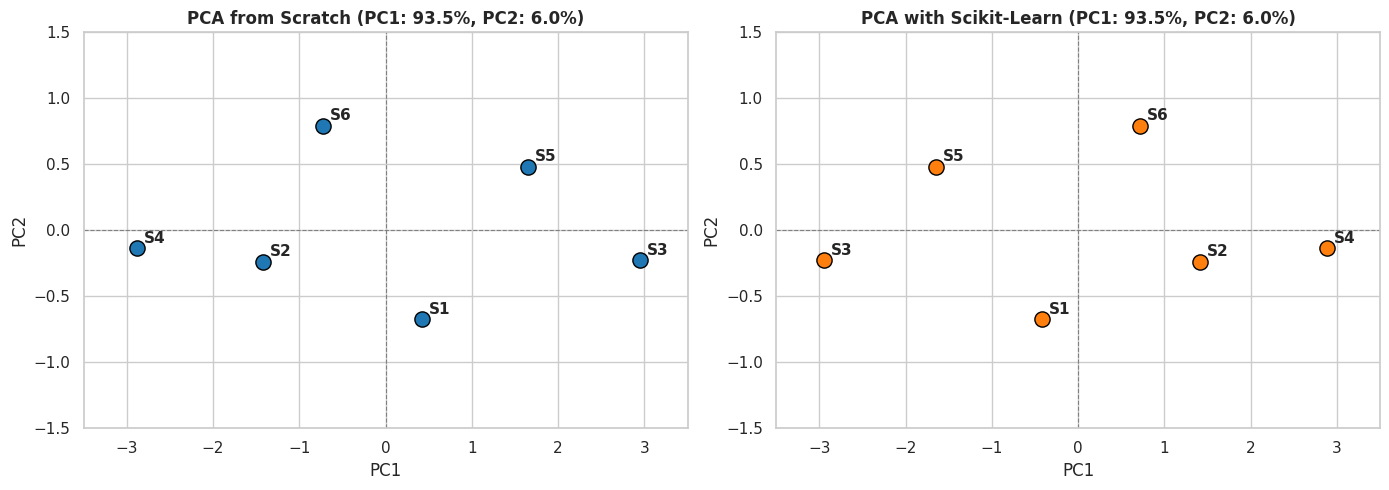

In [17]:
# 16. Two-dimensional projection plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, coords, title, color in [
    (axes[0], F_scratch, f"PCA from Scratch (PC1: {explained_var_ratio[0]*100:.1f}%, PC2: {explained_var_ratio[1]*100:.1f}%)", "#1f77b4"),
    (axes[1], F_sklearn, f"PCA with Scikit-Learn (PC1: {sk_var_ratio[0]*100:.1f}%, PC2: {sk_var_ratio[1]*100:.1f}%)", "#ff7f0e")
]:
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
    ax.scatter(coords[:, 0], coords[:, 1], color=color, s=120, edgecolors="black", zorder=4)
    for i, name in enumerate(df_grades.index):
        ax.annotate(name, (coords[i, 0] + 0.08, coords[i, 1] + 0.04), fontsize=11, fontweight="bold")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-1.5, 1.5)

plt.tight_layout()
plt.show()


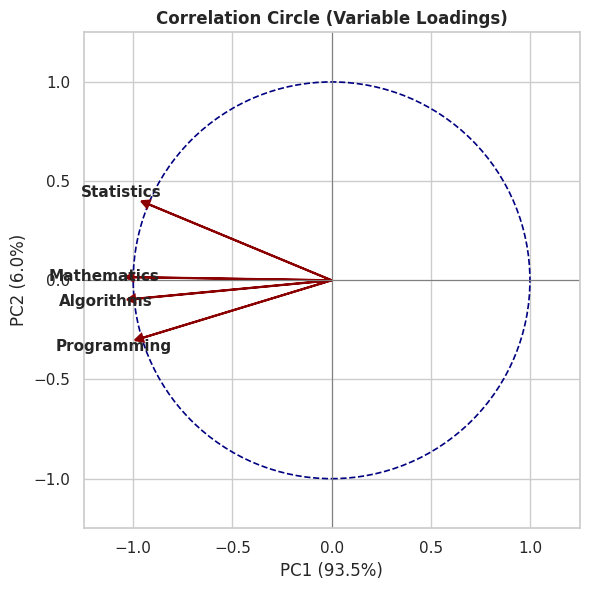

In [18]:
# Correlation circle
fig, ax = plt.subplots(figsize=(6, 6))
circle = plt.Circle((0, 0), 1.0, color="navy", fill=False, linestyle="--", linewidth=1.2)
ax.add_patch(circle)
ax.axhline(0, color="gray", linestyle="-", linewidth=0.8)
ax.axvline(0, color="gray", linestyle="-", linewidth=0.8)

loadings_1 = np.sqrt(eigenvalues[0]) * W[:, 0]
loadings_2 = np.sqrt(eigenvalues[1]) * W[:, 1]

for j, feat in enumerate(df_grades.columns):
    ax.arrow(0, 0, loadings_1[j], loadings_2[j], head_width=0.04, head_length=0.04, fc="darkred", ec="darkred", linewidth=1.5)
    ax.text(loadings_1[j]*1.15, loadings_2[j]*1.15, feat, fontsize=11, fontweight="bold", ha="center", va="center")

ax.set_xlim(-1.25, 1.25)
ax.set_ylim(-1.25, 1.25)
ax.set_aspect("equal")
ax.set_xlabel(f"PC1 ({explained_var_ratio[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({explained_var_ratio[1]*100:.1f}%)")
ax.set_title("Correlation Circle (Variable Loadings)", fontweight="bold")
plt.show()


### 17. Explanation of Differences & Sign Changes

1. **Sign Reflection in Principal Component 1:**
   - In our scratch implementation, the first eigenvector points in the negative direction across all 4 subjects ($[-0.5167, -0.4770, -0.4928, -0.5125]$). In scikit-learn, the SVD routine chose the opposite orientation ($[+0.5167, +0.4770, +0.4928, +0.5125]$).
   - **Linear Algebra Justification:** Eigenvectors satisfy $\mathbf{R} \mathbf{v} = \lambda \mathbf{v}$. Notice that $\mathbf{R}(-\mathbf{v}) = -(\mathbf{R}\mathbf{v}) = -\lambda \mathbf{v} = \lambda(-\mathbf{v})$. Therefore, both $+\mathbf{v}$ and $-\mathbf{v}$ are mathematically valid unit eigenvectors of identical eigenvalue.
   - Geometrically, this represents an isometric reflection across the vertical axis. All pairwise Euclidean distances, relative configurations, clusterings, and variances are preserved.

2. **Eigenvalues vs. Scikit-Learn `explained_variance_`:**
   - Scratch eigenvalue for PC1 is $\lambda_1 = 3.7397$.
   - Scikit-learn reports `explained_variance_` for PC1 as $4.4877$.
   - **Mathematical Reason:** Scikit-learn applies Bessel's sample correction with degrees of freedom $N - 1$:
     $$\text{Var}_{\text{sklearn}} = \text{Var}_{\text{scratch}} \times \frac{N}{N - 1} = 3.7397 \times \frac{6}{5} = 4.4877$$
   - The normalized **explained variance ratios are 100% identical**: $93.49\%$ and $6.01\%$.

---

### 18. Variance Retained & Educational Interpretation of Findings

- **Total Variance Retained:**
  $$\text{PC1 } (93.49\%) + \text{PC2 } (6.01\%) = \mathbf{99.50\%}$$
  By projecting from 4 original dimensions down to 2 dimensions, we preserve **$99.50\%$** of the dataset's total information, losing only a negligible $0.50\%$.

- **Educational Interpretation:**
  1. **Principal Component 1 (General Academic Performance — 93.49%):**
     - All 4 subjects load heavily in the same direction. Students with high grades in one subject systematically excel in all other subjects due to strong positive inter-subject correlation ($r > 0.77$).
     - **Student $S_4$** achieves the highest overall achievement (scores $17, 16, 18, 17$).
     - **Student $S_3$** has the lowest overall achievement (scores $8, 9, 10, 9$).
  2. **Principal Component 2 (Curricular Specialization — 6.01%):**
     - Contrasts Statistics ($+0.782$) against Programming ($-0.592$) and Algorithms ($-0.191$).
     - **Students $S_6$ and $S_5$** demonstrate greater proficiency in Statistics relative to coding.
     - **Students $S_1$ and $S_4$** demonstrate greater proficiency in Programming relative to theoretical Statistics.
